# Results for Regression Network

## Sigmoid network

In [37]:
import matplotlib.pyplot as plt
from neural_network import NeuralNetwork
from utils import *
from runge_data import runge_data, runge_function
import numpy as np
from sklearn.model_selection import train_test_split
import optax

In [38]:
# generating and scaling the runge data
rs = 2026
x, y = runge_data(rs=rs)
y = y.reshape(-1, 1)
X = x.reshape(-1, 1)
ts = 0.2                # test size

Testing automatic differentiation against analytic derivative of the cost function.

In [50]:
from test_gradient import *
run_all()

Backprop vs JAX
linear, identity                  max |Δ| = 2.220e-16  OK
1 hidden, sigmoid                 max |Δ| = 5.551e-17  OK
2 hidden, sigmoid                 max |Δ| = 1.110e-16  OK
1 hidden, ReLU                    max |Δ| = 2.220e-16  OK
2 hidden, ReLU                    max |Δ| = 0.000e+00  OK
L2, lambda=0.1                    max |Δ| = 1.110e-16  OK
L1, lambda=0.1                    max |Δ| = 2.220e-16  OK

OLS recovery
OLS recovery, degree 2            max |Δ| = 8.122e-17  OK
    eta = 0.4831  (eta_max = 0.9662)

All tests passed.


Let's initialize the neural network. Because we are focusing on a regression problem, the output function is linear, in this case, the identity. 

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=rs)

def fit_single_layer(X_tr, y_tr):
    net = NeuralNetwork(1, [50, 1], [sigmoid, identity], [sigmoid_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=rs)
    net.train_sgd(X_tr, y_tr, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

def fit_double_layer(X_tr, y_tr):
    net = NeuralNetwork(1, [50, 50, 1], [sigmoid, sigmoid, identity], [sigmoid_der, sigmoid_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=rs)
    net.train_sgd(X_tr, y_tr, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

mse1, sem1 = cv_mse(X_train, y_train, fit_single_layer)
mse2, sem2 = cv_mse(X_train, y_train, fit_double_layer)
print("MSE FFNN 1 hidden layers: ", mse1, "+-", sem1)
print("MSE FFNN 2 hidden layers: ", mse2, "+-", sem2)

MSE FFNN 1 hidden layers:  0.012661027268547004 +- 0.0009672789381806938
MSE FFNN 2 hidden layers:  0.01211621200723934 +- 0.0010385183097939284


Let's find the best learning rate and optimizer by cross validation!

PGD 0.001 0.11469923414608885 +- 0.015462525021664501
PGD 0.01 0.11310345641931108 +- 0.015947536417635164
PGD 0.1 0.10845205343079253 +- 0.015606238776232866
SGD + RMSprop 0.001 0.10577131912342834 +- 0.015215614476924905
SGD + RMSprop 0.01 0.021387394835325216 +- 0.004541133719578794
SGD + RMSprop 0.1 0.019191061834103625 +- 0.002610096273360187
SGD + Adam 0.001 0.10792934382346364 +- 0.015149593923838285
SGD + Adam 0.01 0.012661027268547004 +- 0.0009672789381806938
SGD + Adam 0.1 0.016372365270187112 +- 0.004010101322670877
PGD 0.001 0.11266880476118277 +- 0.016126032453323363
PGD 0.01 0.11276260923676759 +- 0.016121236568099457
PGD 0.1 0.11292158072400622 +- 0.0162265175312247
SGD + RMSprop 0.001 0.07154791691100651 +- 0.013424514083131885
SGD + RMSprop 0.01 0.016761711522896548 +- 0.004801086025361232
SGD + RMSprop 0.1 0.024644402210115525 +- 0.006972958922270938
SGD + Adam 0.001 0.04199334030227795 +- 0.007486828834217002
SGD + Adam 0.01 0.01211621200723934 +- 0.00103851830979392

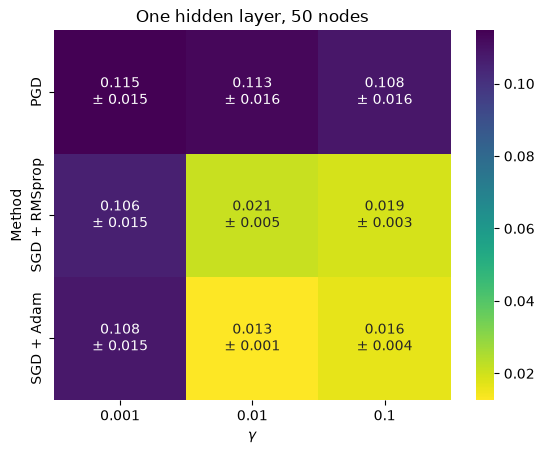

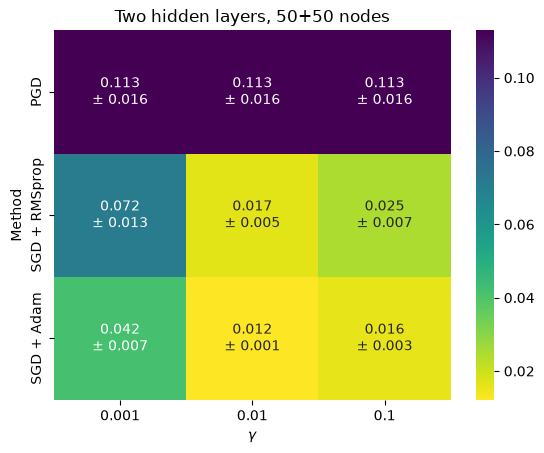

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=rs)
x_test = X_test[:, 0]

sizes_1 = [50, 1]
sizes_2 = [50, 50, 1]          # two hidden layers, 100 nodes in total
gammas = np.logspace(-3, -1, 3) # 0.001, 0.01, 0.1
n_epochs = 500
batch_size = 16

def make_fit(sizes, optimizer, method):
    n_hidden = len(sizes) - 1
    acts = [L1] * n_hidden + [identity]
    ders = [L1_der] * n_hidden + [identity_der]
    def fit(X_tr, y_tr):
        net = NeuralNetwork(1, sizes, acts, ders, mse, mse_der, lmbda=0.0, seed=rs)
        if method == "pgd":
            net.train_pgd(X_tr, y_tr, optimizer, n_epochs=n_epochs)
        else:
            net.train_sgd(X_tr, y_tr, optimizer, n_epochs=n_epochs, batch_size=batch_size)
        return net
    return fit

methods = {
    "PGD":            lambda g: ("pgd", optax.sgd(g)),
    "SGD + RMSprop":  lambda g: ("sgd", optax.rmsprop(g)),
    "SGD + Adam":     lambda g: ("sgd", optax.adam(g)),
}

def lr_grid(sizes):
    mean = np.zeros((len(methods), len(gammas)))
    sem  = np.zeros((len(methods), len(gammas)))
    for i, (name, make_opt) in enumerate(methods.items()):
        for j, g in enumerate(gammas):
            method, opt = make_opt(float(g))
            mean[i, j], sem[i, j] = cv_mse(X_train, y_train, make_fit(sizes, opt, method))
            print(name, g, mean[i, j], "+-", sem[i, j])

    return mean, sem

mean_1, sem_1 = lr_grid(sizes_1)
mean_2, sem_2 = lr_grid(sizes_2)

plot_heatmap(mean_1, sem_1, [f"{g:.3g}" for g in gammas], list(methods),
             r"$\gamma$", "Method", "One hidden layer, 50 nodes")
plot_heatmap(mean_2, sem_2, [f"{g:.3g}" for g in gammas], list(methods),
             r"$\gamma$", "Method", "Two hidden layers, 50+50 nodes")

We see that the two-hidden layer network overall does better than the one-layer hidden network. The optimal learning rate was gamma = 0.01 with SGD + Adam as the optimal method. 

Now find mse for the optimal network!

In [ ]:
def fit_optimal(X_train, y_train):
    net = NeuralNetwork(1, [50, 50, 1], [sigmoid, sigmoid, identity], [sigmoid_der, sigmoid_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=rs)
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

net_optimal = fit_optimal(X_train, y_train)
y_pred = net_optimal.predict(X_test)

f_test = runge_function(x_test) - y_train.mean()

mse_noise = mse(y_pred, y_test)
mse_runge = mse(y_pred, f_test)

print("MSE vs noisy test:", mse_noise)
print("MSE vs true f:    ", mse_runge)
    

MSE vs noisy test: 0.008696913662018184
MSE vs true f:     0.061869474715251185


Of curiosity, we plot the optimal MSE for the one-hidden layer network also. The optimal parameters were gamma = 0.01 and SGD  + Adam.

In [ ]:
def fit_optimal(X_train, y_train):
    net = NeuralNetwork(1, [50, 1], [sigmoid, identity], [sigmoid_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=rs)
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

net_optimal = fit_optimal(X_train, y_train)
y_pred = net_optimal.predict(X_test)

f_test = runge_function(x_test) - y_train.mean()

mse_noise = mse(y_pred, y_test)
mse_runge = mse(y_pred, f_test)

print("MSE vs noisy test:", mse_noise)
print("MSE vs true f:    ", mse_runge)

MSE vs noisy test: 0.010836587821626144
MSE vs true f:     0.05438681485699233


Keep track of accuracy on test data while training (epochs). If accuracy on test stops improving, then stop training. Called "early stopping. Using validation data to fit hyperparameters, so that we do not overfit hyper parameters to the test data.

## ReLU and Leaky ReLU

Now lets jump to part c and investigate two new activation functions.
We keep the best optimizer and learning rate from earlier, which was adam and gamma = 0.01, and instead investigate the mse as a function of width and depth in the network.

1 10 0.011351786111781868 +- 0.0010003114883720126
1 25 0.01303075964449763 +- 0.0012685369217616826
1 50 0.012661027268547004 +- 0.0009672789381806938
1 100 0.01475407916313191 +- 0.000669619869733837
2 10 0.01129261614684491 +- 0.0007982533697755613
2 25 0.011451516072208451 +- 0.0008902685672698419
2 50 0.01211621200723934 +- 0.0010385183097939284
2 100 0.012070042280627176 +- 0.0010178840648245285
3 10 0.011514361761015774 +- 0.0009007368398195815
3 25 0.012441422159120207 +- 0.0011237262284870667
3 50 0.013376777197201465 +- 0.001215177172392594
3 100 0.013846120709720532 +- 0.0007759648738480292
4 10 0.011475134156970638 +- 0.0010813324989089055
4 25 0.012043747547163787 +- 0.001016935678530156
4 50 0.013282390242225403 +- 0.0014826453153603991
4 100 0.014572786459426931 +- 0.001761633921611306
1 10 0.029923629281353604 +- 0.011392407365983218
1 25 0.012202904649272425 +- 0.0016382881789976528
1 50 0.012122228341325664 +- 0.001628728493859171
1 100 0.013966200715361152 +- 0.00141

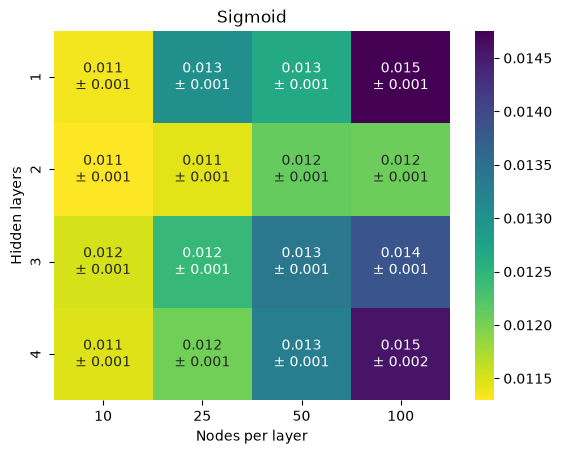

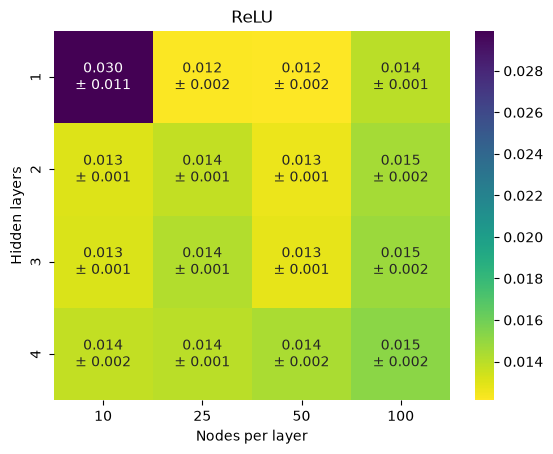

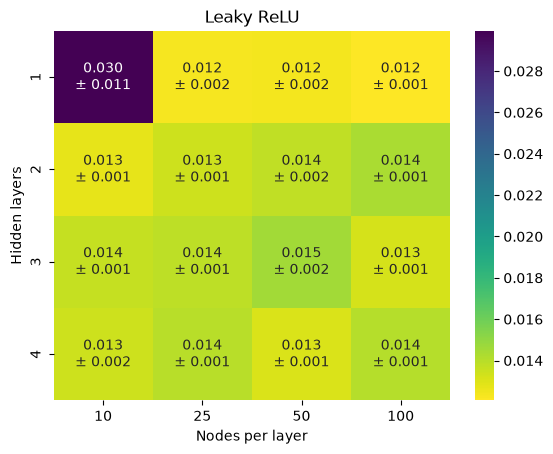

In [ ]:
optimizer = optax.adam(0.01)
depths = [1, 2, 3, 4]
widths = [10, 25, 50, 100]
activations = {
    "Sigmoid":     (sigmoid, sigmoid_der, None),
    "ReLU":        (ReLU, ReLU_der, "He"),
    "Leaky ReLU":  (leaky_ReLU, leaky_ReLU_der, "He"),
}

def make_fit(n_hidden, width, act, der, init):
    sizes = [width] * n_hidden + [1]
    acts = [act] * n_hidden + [identity]
    ders = [der] * n_hidden + [identity_der]
    def fit(X_tr, y_tr):
        net = NeuralNetwork(1, sizes, acts, ders, mse, mse_der, lmbda=0.0, seed=rs, init=init)
        net.train_sgd(X_tr, y_tr, optimizer, n_epochs=n_epochs, batch_size=batch_size)
        return net
    return fit

def arch_grid(act, der, init):
    mean = np.zeros((len(depths), len(widths)))
    sem  = np.zeros((len(depths), len(widths)))
    for i, d in enumerate(depths):
        for j, w in enumerate(widths):
            mean[i, j], sem[i, j] = cv_mse(X_train, y_train, make_fit(d, w, act, der, init))
            print(d, w, mean[i, j], "+-", sem[i, j])
    return mean, sem

grids = {name: arch_grid(act, der, init) for name, (act, der, init) in activations.items()}
for name, (mean, sem) in grids.items():
    plot_heatmap(mean, sem, widths, depths, "Nodes per layer", "Hidden layers", name)

### The MSE's for the optimized ReLU, Leaky ReLU and Sigmoid comes here!

In [49]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=rs)

def test_mse(net, X_te, y_te):
    """Returns MSE"""
    return float(mse(net.predict(X_te), y_te))

def repeat(fit, n=1, base_seed=rs):
    """Mean and std over optimal fit"""
    scores = [test_mse(fit(X_train, y_train, seed=base_seed + i), X_test, y_test)
              for i in range(n)]
    scores = np.array(scores)

    return scores.mean(), scores.std(ddof=1) / np.sqrt(n)

def fit_optimal_sigmoid(X_train, y_train, seed):
    """Optimal parameters for sigmoid"""
    net = NeuralNetwork(1, [10, 1], [sigmoid, identity], [sigmoid_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=seed)
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

def fit_optimal_relu(X_train, y_train, seed):
    net = NeuralNetwork(1, [25, 1], [ReLU, identity], [ReLU_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=seed, init="He")
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

def fit_optimal_lrelu(X_train, y_train, seed):
    net = NeuralNetwork(1, [25, 1], [leaky_ReLU, identity], [leaky_ReLU_der, identity_der],
                        mse, mse_der, lmbda=0.0, seed=seed, init="He")
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

for name, fit in [("Sigmoid", fit_optimal_sigmoid), ("ReLU", fit_optimal_relu), ("Leaky ReLU", fit_optimal_lrelu),
                  ("L2", fit_optimal_L2), ("L1", fit_optimal_L1)]:
    mean, sem = repeat(fit)
    print(f"{name:12} {mean:.4f} ± {sem:.4f}")

Sigmoid      0.0079 ± nan
ReLU         0.0105 ± nan
Leaky ReLU   0.0108 ± nan
L2           0.0070 ± nan
L1           0.0069 ± nan


## Regularization terms L1 and L2

Use of LLM:

The code in this cell is written by a LLM


0.0 0.001 0.012577242697641159 +- 0.0012210737374394557
0.0 0.01 0.01266435516791485 +- 0.0012331712522388619
0.0 0.1 0.017284536892188656 +- 0.0028005184986686998
9.999999999999999e-06 0.001 0.01283804420226832 +- 0.001179248231612319
9.999999999999999e-06 0.01 0.012976018181696492 +- 0.0014008232172748984
9.999999999999999e-06 0.1 0.012792442293712297 +- 0.0021024838246628094
0.0001 0.001 0.012207974823507455 +- 0.0011817368859150833
0.0001 0.01 0.012841334445280572 +- 0.0013202345570345999
0.0001 0.1 0.014856422178297574 +- 0.002201181001486881
0.001 0.001 0.012854758737735691 +- 0.0013009588458398399
0.001 0.01 0.012008462025019987 +- 0.0013775979622405155
0.001 0.1 0.01359599506914794 +- 0.0009769125342262257
0.01 0.001 0.012931495317634415 +- 0.002012074305781027
0.01 0.01 0.019146447236786563 +- 0.0035948817595977396
0.01 0.1 0.02764748937844578 +- 0.005305870043151167
0.1 0.001 0.0426227653502308 +- 0.007378644844445725
0.1 0.01 0.1130378303743292 +- 0.01630313525227509
0.1 0.1

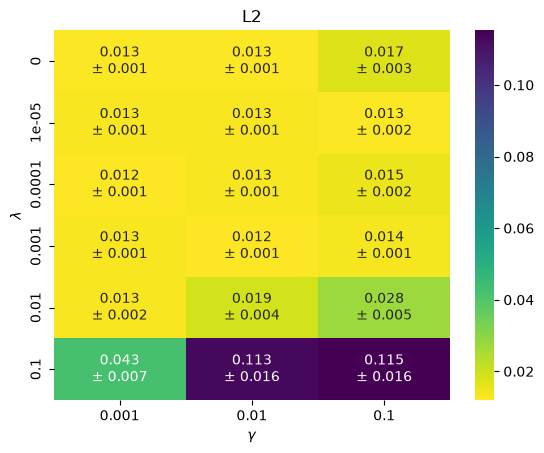

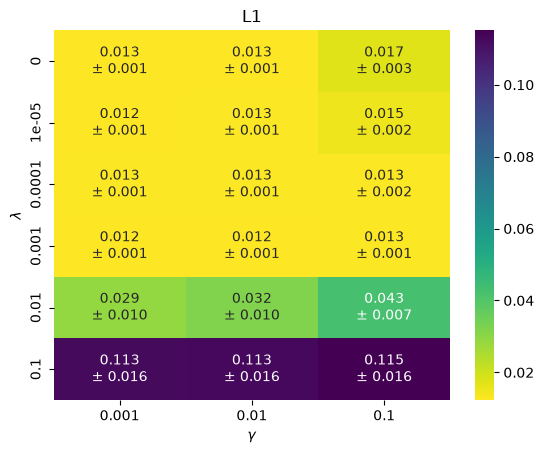

1 25 0.013592821998544766 +- 0.0013506513918877363
1 50 0.014668002147864775 +- 0.002413536157508352
1 100 0.014265011892987681 +- 0.002450956283487538
2 25 0.012404427221454295 +- 0.0010760184891632609
2 50 0.012008462025019987 +- 0.0013775979622405155
2 100 0.012700492486579406 +- 0.001276724719433963
3 25 0.012296499172603823 +- 0.0014285886855017525
3 50 0.01251915770903567 +- 0.0015769841281499887
3 100 0.012521997258283523 +- 0.0015043801448974326
1 25 0.015225721041178728 +- 0.0019001196291320182
1 50 0.014900579104454855 +- 0.001938606388803487
1 100 0.0159716658411259 +- 0.0026210254302738824
2 25 0.011160583846630738 +- 0.0007419373654616805
2 50 0.012332561391316721 +- 0.001213058215052588
2 100 0.012459073932736871 +- 0.0009873301530853153
3 25 0.011731337649683395 +- 0.0010641848982973106
3 50 0.01086838976947244 +- 0.0005571245328159691
3 100 0.011429894672265312 +- 0.0008322961477302067


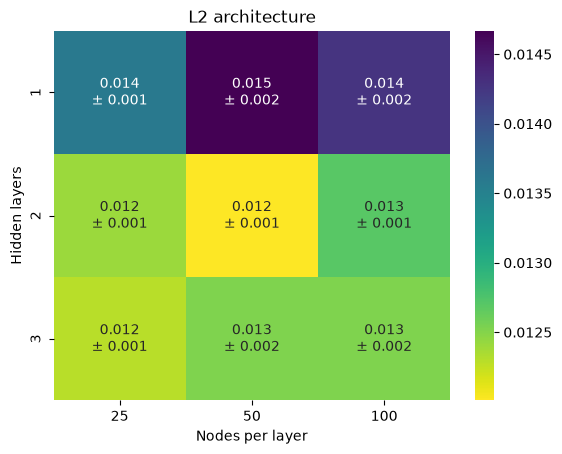

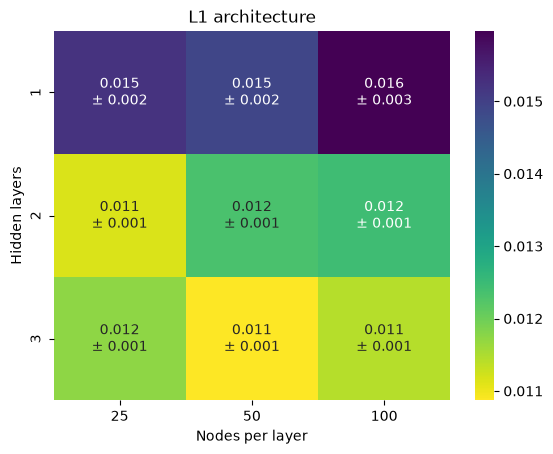

In [ ]:
# --- architecture from part c ---
n_hidden, width = 2, 50         
act, der, init  = ReLU, ReLU_der, "He"

lmdas  = np.concatenate(([0.0], np.logspace(-5, -1, 5)))  # 0, 1e-5, ..., 1e-1
gammas = np.logspace(-3, -1, 3)                           # 0.001, 0.01, 0.1
depths = [1, 2, 3]
widths = [25, 50, 100]

def make_fit(lmbda, gamma, penalty, n_hidden=n_hidden, width=width):
    sizes = [width] * n_hidden + [1]
    def fit(X_tr, y_tr):
        net = NeuralNetwork(1, sizes, [act]*n_hidden+[identity], [der]*n_hidden+[identity_der],
                            mse, mse_der, lmbda=lmbda, seed=rs, init=init, penalty=penalty)
        net.train_sgd(X_tr, y_tr, optax.adam(gamma), n_epochs=n_epochs, batch_size=batch_size)
        return net
    return fit

# 1. lambda x gamma, fixed architecture
l2_mean, l2_sem = run_grid(X_train, y_train,
                           lambda l, g: make_fit(l, g, "l2"), lmdas, gammas)
l1_mean, l1_sem = run_grid(X_train, y_train,
                           lambda l, g: make_fit(l, g, "l1"), lmdas, gammas)

plot_heatmap(l2_mean, l2_sem, [f"{g:.3g}" for g in gammas], [f"{l:.3g}" for l in lmdas],
             r"$\gamma$", r"$\lambda$", "L2")
plot_heatmap(l1_mean, l1_sem, [f"{g:.3g}" for g in gammas], [f"{l:.3g}" for l in lmdas],
             r"$\gamma$", r"$\lambda$", "L1")

l2_lmbda, l2_gamma, _ = best_cell(l2_mean, lmdas, gammas)
l1_lmbda, l1_gamma, _ = best_cell(l1_mean, lmdas, gammas)

# 2. depth x width at the best (lambda, gamma)
l2_arch, l2_arch_sem = run_grid(X_train, y_train,
    lambda d, w: make_fit(l2_lmbda, l2_gamma, "l2", n_hidden=d, width=w), depths, widths)
l1_arch, l1_arch_sem = run_grid(X_train, y_train,
    lambda d, w: make_fit(l1_lmbda, l1_gamma, "l1", n_hidden=d, width=w), depths, widths)

plot_heatmap(l2_arch, l2_arch_sem, widths, depths, "Nodes per layer", "Hidden layers", "L2 architecture")
plot_heatmap(l1_arch, l1_arch_sem, widths, depths, "Nodes per layer", "Hidden layers", "L1 architecture")

l2_depth, l2_width, _ = best_cell(l2_arch, depths, widths)
l1_depth, l1_width, _ = best_cell(l1_arch, depths, widths)

The MSE's for the optimized L1 and L2 regularization comes here!

In [48]:
def fit_optimal_L1(X_train, y_train, seed):
    net = NeuralNetwork(1, [50, 50, 50, 1], [ReLU, ReLU, ReLU, identity], [ReLU_der, ReLU_der, ReLU_der, identity_der],
                        mse, mse_der, lmbda=0.001, seed=seed, penalty="l1", init="He")
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net

def fit_optimal_L2(X_train, y_train, seed):
    net = NeuralNetwork(1, [50, 50, 1], [ReLU, ReLU, identity], [ReLU_der, ReLU_der, identity_der],
                        mse, mse_der, lmbda=0.001, seed=seed, init="He")
    net.train_sgd(X_train, y_train, optax.adam(0.01), n_epochs=500, batch_size=16)
    return net


for name, fit in [("L2", fit_optimal_L2), ("L1", fit_optimal_L1)]:
    mean, sem = repeat(fit)
    print(f"{name:12} {mean:.4f} ± {sem:.4f}")

L2           0.0070 ± nan
L1           0.0069 ± nan
